In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
import httpx
import plotly.express as px
import plotly.io as pio
import unidecode
import seaborn as sns

# Indice




# Ingesta de Datos

In [74]:
# df_bolsa_cereales_nacion = pd.read_excel("./../data/raw/datos_bolsa_cereales_nacion.csv") <-- DESCARTADO POR USAR ZONA PAS
df_bolsa_cereales_cba = pd.read_csv("./../data/raw/datos_bolsa_granos_cba.csv")
df_estimaciones_agricolas = pd.read_csv("./../data/raw/datos_estimaciones.csv",encoding="utf-8-sig")

# Preparacion de Indice de Cultivo

**NOTA**: Si bien los indices de cultivos al ser la proporción del rendimiento en grano respecto a la biomasa aérea total de la planta pueden variar por mejroas geneticas se suponen constantes y se utiliza los del paper como referencia

In [75]:
import pandas as pd

data = {
    "Cultivo": [
        "maíz", "soja", "trigo", "girasol", "maní", "garbanzo",
        "sorgo", "cebada", "centeno", "avena", "poroto",
        # Nuevos agregados
        "ajo",
        "colza",
        "papa",
        "lino",
        "arroz",
        "algodón"
    ],
    "IC": [
        0.47, 0.45, 0.35, 0.37, 0.40, 0.26,
        0.35, 0.53, 0.22, 0.35, 0.45,
        # Nuevos agregados
        0.55,   # ajo
        0.28,   # colza
        0.74,   # papa
        0.40,   # lino (valor representativo documentado)
        0.45,   # arroz (valor representativo del rango moderno)
        0.30    # algodón (lint HI representativo)
    ],
    "Fuente bibliográfica": [
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Raposo (2024)",
        "Haro (2022), Promedio variedad granoleico",
        "Promedio de lo obtenido por Apáez-Barrios (2017) y Ramacciotti (2015)",
        "Promedio de híbridos obtenido por Zamer y Chiarelli",
        "Cuda (2014)",
        "Zubiaga et al. (2023)",
        "Promedios obtenidos por Zubiaga et al. (2023)",
        "Ortega (2001)",
        # Nuevos agregados
        "Rizzalli, Villalobos & Orgaz (2002). European Journal of Agronomy",
        "Unkovich et al. / Advances in Agronomy (compilado ~2010); Lu et al. (2016)",
        "Xu et al. (análisis QUEFTS, Agronomy Journal); rango documentado 0.70-0.85",
        "Estudios de componentes de rendimiento (ADAS/AHDB y ensayos de monocultivo)",
        "Hay (1995) y estudios recientes de riego/N (rango moderno 0.40-0.55)",
        "Estudios regionales (Xinjiang y revisiones globales de lint HI)"
    ]
}

df_IC = pd.DataFrame(data)

df_IC['FR'] = (1 - df_IC['IC']) / df_IC['IC']

df_IC.head(20)

,Cultivo,IC,Fuente bibliográfica,FR
0,maíz,0.47,Bolsa de Cereales de Buenos Aires (2015),1.127660
1,soja,0.45,Bolsa de Cereales de Buenos Aires (2015),1.222222
2,trigo,0.35,Bolsa de Cereales de Buenos Aires (2015),1.857143
3,girasol,0.37,Raposo (2024),1.702703
4,maní,0.40,"Haro (2022), Promedio variedad granoleico",1.500000
5,garbanzo,0.26,Promedio de lo obtenido por Apáez-Barrios (201...,2.846154
6,sorgo,0.35,Promedio de híbridos obtenido por Zamer y Chia...,1.857143
7,cebada,0.53,Cuda (2014),0.886792
8,centeno,0.22,Zubiaga et al. (2023),3.545455
9,avena,0.35,Promedios obtenidos por Zubiaga et al. (2023),1.857143


### Markdown de aclaración (cultivos agregados + fuentes con links)

| Cultivo   | IC usado | Fuente y link |
|-----------|----------|---------------|
| **ajo**   | 0.55    | Rizzalli, R.H.; Villalobos, F.J.; Orgaz, F. (2002). *Radiation interception, radiation-use efficiency and dry matter partitioning in garlic (Allium sativum L.)*. European Journal of Agronomy 18(1-2): 33-43. HI reportado ≈0.55.<br>Link: https://www.sciencedirect.com/science/article/abs/pii/S1161030102000941<br>También respaldado por Escalante-Estrada et al. (2019) Terra Latinoamericana (IC ≈0.66–0.69 / 68%). |
| **colza** | 0.28    | Unkovich et al. (compilado en Advances in Agronomy) y Lu et al. (2016). Media ≈0.28 (rango documentado 0.04–0.42, típico 0.20–0.28).<br>Link de referencia: https://www.sciencedirect.com/science/article/abs/pii/S0378429016306840 y estudios de *Brassica napus* citados en PMC (ej. https://pmc.ncbi.nlm.nih.gov/articles/PMC6507709/). |
| **papa**  | 0.74    | Xu et al. (análisis QUEFTS en China, n=654). Media 0.74 (rango 0.40–0.95; 95% entre 0.52–0.87). Valores frecuentes 0.70–0.85 en literatura.<br>Link: https://acsess.onlinelibrary.wiley.com/doi/abs/10.2134/agronj2018.09.0572 |
| **lino**  | 0.40    | Valores documentados en ensayos de componentes de rendimiento (≈0.38) y monocultivos (hasta ≈0.51). Se usó 0.40 como representativo del rango reportado.<br>Referencias: estudios ADAS/AHDB y papers de *Linum usitatissimum* (ej. diversidad de HI en mezclas: https://pmc.ncbi.nlm.nih.gov/articles/PMC7611346/). |
| **arroz** | 0.45    | Rango moderno documentado 0.34–0.55 (frecuentemente 0.40–0.55; algunos ensayos ≥0.55–0.62). Se usó 0.45 como valor central representativo.<br>Fuente clásica: Hay (1995) Annals of Applied Biology + estudios recientes de riego/N. |
| **algodón** | 0.30  | Lint harvest index típico en regiones áridas ≈0.28–0.33 (Xinjiang); rangos globales más amplios. Se usó 0.30 como representativo.<br>Link: https://doi.org/10.3390/agronomy15030743 |

**Notas importantes:**
- No se agregaron cultivos sin dato confiable (alpiste, jojoba, yerba mate, tung, té, banana, cítricos, caña de azúcar, cebolla con IC estándar, etc.).
- Los valores de IC originales de la tabla se mantuvieron intactos.
- El cálculo de `FR` se aplica automáticamente a todos los registros (incluyendo los nuevos).

# Tratamiento de Datos

## Valores Nulos

In [76]:
print("================ BOLSA DE CEREALES CBA ================")
print(df_bolsa_cereales_cba.info())
print("================ MINISTERIO DE AGRICULTURA GANADERIA Y PESCA DE LA NACION ================")
print(df_estimaciones_agricolas.info())

================ BOLSA DE CEREALES CBA ================
<class 'pandas.DataFrame'>
RangeIndex: 4094 entries, 0 to 4093
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   PROVINCIA                        4094 non-null   str    
 1   DEPARTAMENTO                     4094 non-null   str    
 2   CULTIVO                          4094 non-null   str    
 3   CAMPAÑA                          4094 non-null   str    
 4   SEMBRADAS                        4094 non-null   float64
 5   COSECHADAS                       4094 non-null   float64
 6   RENDIMIENTO                      3850 non-null   float64
 7   RENDIMIENTO GRANO LIMPIO Y SECO  215 non-null    float64
 8   PRODUCCIÓN                       3850 non-null   float64
 9   PRODUCCIÓN GRANO LIMPIO Y SECO   215 non-null    float64
dtypes: float64(6), str(4)
memory usage: 320.0 KB
None
================ MINISTERIO DE AGRICULTURA GANADE

**NOTA**: Notamos que solo el dataset de la bolsa de cereales de cba tiene nulos, es por esto que vamos a proseguir solo con dicho dataset

### Visualizacion de Nulos

<Axes: >

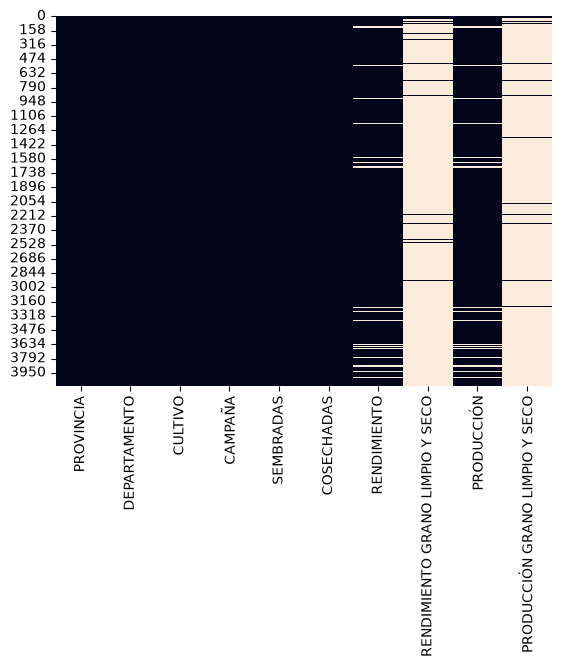

In [77]:
import seaborn as sns
sns.heatmap(df_bolsa_cereales_cba.isnull(), cbar=False)

**NOTA**: Observamos que debido a la falta de datos en columanas Limpio y Seco hay que desestimarlas (eliminarlas). Adicionalmente debemos notar que como el rendimiento es produccion sobre area entonces los nulos de rendimiento se dan cuando tengo nulos en Prouccion.

### Limpieza Dataset CBA

In [78]:
# Eliminamos Columnas Limpio y Seco

df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba.drop(columns=['RENDIMIENTO GRANO LIMPIO Y SECO','PRODUCCIÓN GRANO LIMPIO Y SECO'])

# Eliminamos filas con Nulos

df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba_cleaned.dropna()

print(df_bolsa_cereales_cba_cleaned.info())

<class 'pandas.DataFrame'>
Index: 3850 entries, 0 to 4093
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3850 non-null   str    
 1   DEPARTAMENTO  3850 non-null   str    
 2   CULTIVO       3850 non-null   str    
 3   CAMPAÑA       3850 non-null   str    
 4   SEMBRADAS     3850 non-null   float64
 5   COSECHADAS    3850 non-null   float64
 6   RENDIMIENTO   3850 non-null   float64
 7   PRODUCCIÓN    3850 non-null   float64
dtypes: float64(4), str(4)
memory usage: 270.7 KB
None


<Axes: >

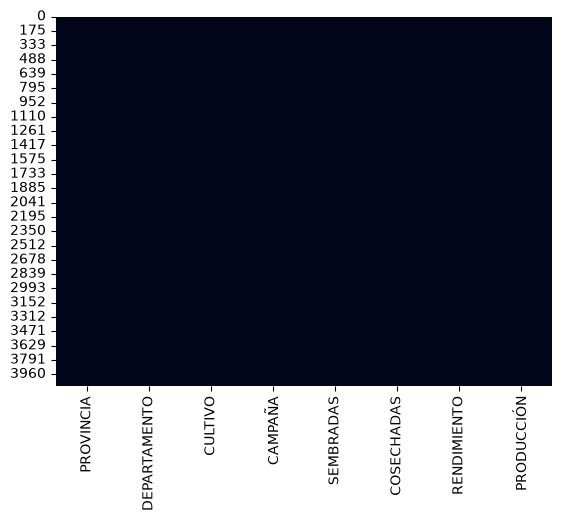

In [79]:
sns.heatmap(df_bolsa_cereales_cba_cleaned.isnull(), cbar=False)

## Limpieza de Columnas

### Cultivo

#### Bolsa de Cereales de CBA

In [80]:
print(sorted(df_bolsa_cereales_cba_cleaned["CULTIVO"].unique()))

['GARBANZO', 'GIRASOL', 'MAIZ', 'MANI', 'SOJA', 'SORGO', 'SORGO ', 'TRIGO', 'TRIGO CANDEAL']


**NOTA**: Observamos que todos los valores estan em mayusculas ademas de que hay errores porque algunos de ellos incluyen un espacio asi que pasamos a dejarlos en minusculas y sin espacios innecesarios. Adicionalemnte eliminaremos acentos y ñ para que sea mas facil trbajar por temas de codificaciones.

In [81]:
import unicodedata

# NFKD descompone é → e + ´, y ñ → n + ˜
#.encode('ascii', 'ignore').decode('ascii') descarta los acentos/tilde que quedaron sueltos elimina acentos Y ñ 
#.strip().lower() → minúsculas sin espacios

def clean_str(s: str) -> str:
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode('ascii')
    return s.strip().lower()


In [82]:
df_bolsa_cereales_cba_cleaned["CULTIVO"] = df_bolsa_cereales_cba_cleaned["CULTIVO"].apply(clean_str)

print(sorted(df_bolsa_cereales_cba_cleaned["CULTIVO"].unique()))

['garbanzo', 'girasol', 'maiz', 'mani', 'soja', 'sorgo', 'trigo', 'trigo candeal']


#### MAGYP (ESTIMACIONES AGRICOLAS)

In [83]:
print(sorted(df_estimaciones_agricolas["Cultivo"].unique()))

['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']


**NOTA**: Observamos que tiene capitalizacion tipo titulo ademas de acentos y ñ por lo que procedemos a limpiar de la misma manera que el dataset de bolsa de cereales de cba 

In [84]:
df_estimaciones_agricolas["Cultivo"] = df_estimaciones_agricolas["Cultivo"].apply(clean_str)

print(sorted(df_estimaciones_agricolas["Cultivo"].unique()))

['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada cervecera', 'cebada forrajera', 'cebada total', 'cebolla total', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa total', 'pomelo', 'poroto alubia', 'poroto negro', 'poroto otros', 'poroto total', 'soja 1ra', 'soja 2da', 'soja total', 'sorgo', 'te', 'trigo candeal', 'trigo total', 'tung', 'yerba mate']


**Nota metodológica**:  
Se identificó la presencia de cultivos registrados con la denominación TOTAL. Dichos registros representan la agregación de todas las variedades correspondientes a un mismo cultivo. Con el fin de evitar duplicaciones y asegurar la consistencia en el análisis, se decidió conservar únicamente aquellos cultivos que incluyen la denominación TOTAL. Los cultivos sin dicha denominación serán considerados únicamente en los casos en que no exista un registro equivalente con la categoría TOTAL para el mismo tipo de cultivo.

In [85]:
df = df_estimaciones_agricolas.copy()

df["Cultivo_base"] = df["Cultivo"].str.replace(" total", "", regex=False)
df["Es_total"] = df["Cultivo"].str.contains("total")

df["Tiene_total"] = (
    df.groupby(["Campaña", "Provincia", "Departamento", "Cultivo_base"])["Es_total"]
      .transform("any")
)

df_filtrado = df[(~df["Tiene_total"]) | (df["Es_total"])]

df_estimaciones_agricolas_cleaned = df_filtrado.rename( 
  columns={
    'Cultivo':'old_Cultivo',
    'Cultivo_base':'Cultivo'
  })

print(sorted(df_estimaciones_agricolas_cleaned['Cultivo'].unique()))

['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada', 'cebada cervecera', 'cebada forrajera', 'cebolla', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa', 'pomelo', 'poroto', 'poroto alubia', 'poroto negro', 'poroto otros', 'soja', 'soja 1ra', 'soja 2da', 'sorgo', 'te', 'trigo', 'trigo candeal', 'tung', 'yerba mate']


### Capaña

vamos a utilizar el formato YYYY/YY como el formato estandar de nuestra columan campaña

In [86]:
# Patrón correcto: 4 dígitos / 2 dígitos (ej. 2024/25)
pattern = r"^\d{4}/\d{2}$"

# Filtrar filas que NO cumplen el patrón
invalid_values_estimaciones = df_estimaciones_agricolas_cleaned.loc[~df_estimaciones_agricolas_cleaned["Campaña"].str.match(pattern, na=False), "Campaña"]
invalid_values_cba = df_bolsa_cereales_cba_cleaned.loc[~df_bolsa_cereales_cba_cleaned["CAMPAÑA"].str.match(pattern, na=False), "CAMPAÑA"]

print("Cantidad de valores fuera de formato YYYY/YY para Estimaciones Agricolas: ", len(invalid_values_estimaciones))
print("Cantidad de valores fuera de formato YYYY/YY para Bolsa de Cereales de CBA: ", len(invalid_values_cba))

Cantidad de valores fuera de formato YYYY/YY para Estimaciones Agricolas:  0
Cantidad de valores fuera de formato YYYY/YY para Bolsa de Cereales de CBA:  0


Observamos que todos los valores estan en formato.

### Provincia

#### Estimaciones Agricolas

In [87]:
print(sorted(df_estimaciones_agricolas_cleaned["Provincia"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Provincia"].unique()))

['BUENOS AIRES', 'CATAMARCA', 'CHACO', 'CHUBUT', 'CORDOBA', 'CORRIENTES', 'ENTRE RIOS', 'FORMOSA', 'JUJUY', 'LA PAMPA', 'LA RIOJA', 'MENDOZA', 'MISIONES', 'NEUQUEN', 'RIO NEGRO', 'SALTA', 'SAN JUAN', 'SAN LUIS', 'SANTA CRUZ', 'SANTA FE', 'SANTIAGO DEL ESTERO', 'TIERRA DEL FUEGO', 'TUCUMAN']
23


**NOTA**: Observamos que todas las provincias estan con capitalizacion ene mayuscula por lo que procedemso a escribirlas en minusculas sin acentos ni ñ.

In [88]:
df_estimaciones_agricolas_cleaned['Provincia'] = df_estimaciones_agricolas_cleaned['Provincia'].apply(clean_str)
print(sorted(df_estimaciones_agricolas_cleaned["Provincia"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Provincia"].unique()))

['buenos aires', 'catamarca', 'chaco', 'chubut', 'cordoba', 'corrientes', 'entre rios', 'formosa', 'jujuy', 'la pampa', 'la rioja', 'mendoza', 'misiones', 'neuquen', 'rio negro', 'salta', 'san juan', 'san luis', 'santa cruz', 'santa fe', 'santiago del estero', 'tierra del fuego', 'tucuman']
23


#### Bolsa de Cereales de Cordoba

In [89]:
print(sorted(df_bolsa_cereales_cba_cleaned['PROVINCIA'].unique()))
print(len(df_bolsa_cereales_cba_cleaned['PROVINCIA'].unique()))

['Buenos Aires', 'Catamarca', 'Córdoba', 'La Pampa', 'San Luis', 'Santiago del Estero', 'Tucumán']
7


**NOTA**: observamos que la capitalicacion es de titulo y tienen caracteres que pueden causar problemas como los ascentos procedemos a sacarlos y cambiar capitalizacion a minuscula.

In [90]:
df_bolsa_cereales_cba_cleaned['PROVINCIA'] = df_bolsa_cereales_cba_cleaned['PROVINCIA'].apply(clean_str)
print(sorted(df_bolsa_cereales_cba_cleaned["PROVINCIA"].unique()))
print(len(df_bolsa_cereales_cba_cleaned["PROVINCIA"].unique()))

['buenos aires', 'catamarca', 'cordoba', 'la pampa', 'san luis', 'santiago del estero', 'tucuman']
7


### Departamentos

#### Estimaciones Agricolas

In [91]:
print(sorted(df_estimaciones_agricolas_cleaned["Departamento"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Departamento"].unique()))

['1 DE MAYO', '12 DE OCTUBRE', '2 DE ABRIL', '25 DE MAYO', '25 de Mayo', '9 DE JULIO', 'ADOLFO ALSINA', 'ADOLFO GONZALES CHAVES', 'AGUIRRE', 'ALBARDON', 'ALBERDI', 'ALBERTI', 'ALMIRANTE BROWN', 'ALUMINE', 'AMBATO', 'ANCASTI', 'ANDALGALA', 'ANELO', 'ANGACO', 'ANTA', 'ANTOFAGASTA DE LA SIERRA', 'APOSTOLES', 'ARAUCO', 'ARRECIFES', 'ATAMISQUI', 'ATREUCO', 'AVELLANEDA', 'AYACUCHO', 'AZUL', 'BAHIA BLANCA', 'BALCARCE', 'BANDA', 'BARADERO', 'BARILOCHE', 'BELEN', 'BELGRANO', 'BELLA VISTA', 'BENITO JUAREZ', 'BERAZATEGUI', 'BERISSO', 'BERMEJO', 'BERON DE ASTRADA', 'BIEDMA', 'BOLIVAR', 'BRAGADO', 'BRANDSEN', 'BURRUYACU', 'CACHI', 'CAFAYATE', 'CAINGUAS', 'CALAMUCHITA', 'CALEU CALEU', 'CALINGASTA', 'CAMPANA', 'CANDELARIA', 'CANUELAS', 'CAPAYAN', 'CAPITAL', 'CAPITAN SARMIENTO', 'CARLOS CASARES', 'CARLOS TEJEDOR', 'CARMEN DE ARECO', 'CASEROS', 'CASTELLANOS', 'CASTELLI', 'CASTRO BARROS', 'CATRILO', 'CAUCETE', 'CERRILLOS', 'CHACABUCO', 'CHALILEO', 'CHAMICAL', 'CHAPALEUFU', 'CHASCOMUS', 'CHICLIGASTA', 'C

**Nota**: para asegurar la homogeneidad de los datos str en el dataset hacemos las mismas transformaciones que para provincias

In [92]:
df_estimaciones_agricolas_cleaned['Departamento'] = df_estimaciones_agricolas_cleaned['Departamento'].apply(clean_str)
print(sorted(df_estimaciones_agricolas_cleaned["Departamento"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Departamento"].unique()))

['1 de mayo', '12 de octubre', '2 de abril', '25 de mayo', '9 de julio', 'adolfo alsina', 'adolfo gonzales chaves', 'aguirre', 'albardon', 'alberdi', 'alberti', 'almirante brown', 'alumine', 'ambato', 'ancasti', 'andalgala', 'anelo', 'angaco', 'anta', 'antofagasta de la sierra', 'apostoles', 'arauco', 'arrecifes', 'atamisqui', 'atreuco', 'avellaneda', 'ayacucho', 'azul', 'bahia blanca', 'balcarce', 'banda', 'baradero', 'bariloche', 'belen', 'belgrano', 'bella vista', 'benito juarez', 'berazategui', 'berisso', 'bermejo', 'beron de astrada', 'biedma', 'bolivar', 'bragado', 'brandsen', 'burruyacu', 'cachi', 'cafayate', 'cainguas', 'calamuchita', 'caleu caleu', 'calingasta', 'campana', 'candelaria', 'canuelas', 'capayan', 'capital', 'capitan sarmiento', 'carlos casares', 'carlos tejedor', 'carmen de areco', 'caseros', 'castellanos', 'castelli', 'castro barros', 'catrilo', 'caucete', 'cerrillos', 'chacabuco', 'chalileo', 'chamical', 'chapaleufu', 'chascomus', 'chicligasta', 'chicoana', 'chi

#### Bolsa de Cereales de CBA

In [93]:
print(sorted(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))
print(len(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))

['25 DE MAYO', '9 DE JULIO', 'ADOLFO ALSINA', 'AGUIRRE', 'ALBERDI', 'AMBATO', 'ATREUCO', 'AVELLANEDA', 'AYACUCHO', 'BANDA', 'BELGRANO', 'BOLIVAR', 'BURRUYACU', 'CALAMUCHITA', 'CAPITAL', 'CARLOS CASARES', 'CARLOS TEJEDOR', 'CATRILO', 'CHACABUCO', 'CHAPALEUFU', 'CHICLIGASTA', 'CHOYA', 'COLON', 'CONHELO', 'COPO', 'CORONEL PRINGLES', 'CRUZ ALTA', 'DAIREAUX', 'EL ALTO', 'FAMAILLA', 'FIGUEROA', 'FLORENTINO AMEGHINO', 'GENERAL PEDERNERA', 'GENERAL PINTO', 'GENERAL ROCA', 'GENERAL SAN MARTIN', 'GENERAL TABOADA', 'GENERAL VILLEGAS', 'GOBERNADOR DUPUY', 'GRAL ARENALES', 'GRAL PEDERNERA', 'GRAL VIAMONTE', 'GRAL. SAN MARTIN', 'GRANEROS', 'GUAMINI', 'GUASAYAN', 'GUATRACHE', 'HIPOLITO YRIGOYEN', 'HUCAL', 'ISCHILIN', 'Ischilin', 'J.B.ALBERDI', 'JIMENEZ', 'JUAN FELIPE IBARRA', 'JUAN MARTIN DE PUEYRREDON', 'JUAREZ CELMAN', 'JUNIN', 'LA COCHA', 'LA PAZ', 'LEALES', 'LEANDRO N ALEM', 'LIBERTADOR SAN MARTIN', 'LINCOLN', 'LOVENTUE', 'LULES', 'MARACO', 'MARCOS JUAREZ', 'MITRE', 'MONTEROS', 'MORENO', 'OJO DE 

**Nota**: para asegurar la homogeneidad de los datos str en el dataset hacemos las mismas transformaciones que para provincias

In [94]:
df_bolsa_cereales_cba_cleaned['DEPARTAMENTO'] = df_bolsa_cereales_cba_cleaned['DEPARTAMENTO'].apply(clean_str)
print(sorted(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))
print(len(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))

['25 de mayo', '9 de julio', 'adolfo alsina', 'aguirre', 'alberdi', 'ambato', 'atreuco', 'avellaneda', 'ayacucho', 'banda', 'belgrano', 'bolivar', 'burruyacu', 'calamuchita', 'capital', 'carlos casares', 'carlos tejedor', 'catrilo', 'chacabuco', 'chapaleufu', 'chicligasta', 'choya', 'colon', 'conhelo', 'copo', 'coronel pringles', 'cruz alta', 'daireaux', 'el alto', 'famailla', 'figueroa', 'florentino ameghino', 'general pedernera', 'general pinto', 'general roca', 'general san martin', 'general taboada', 'general villegas', 'gobernador dupuy', 'gral arenales', 'gral pedernera', 'gral viamonte', 'gral. san martin', 'graneros', 'guamini', 'guasayan', 'guatrache', 'hipolito yrigoyen', 'hucal', 'ischilin', 'j.b.alberdi', 'jimenez', 'juan felipe ibarra', 'juan martin de pueyrredon', 'juarez celman', 'junin', 'la cocha', 'la paz', 'leales', 'leandro n alem', 'libertador san martin', 'lincoln', 'loventue', 'lules', 'maraco', 'marcos juarez', 'mitre', 'monteros', 'moreno', 'ojo de agua', 'pacl

## Unificamos Unidades

### Estimaciones

In [95]:
df_estimaciones_agricolas_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 162041 entries, 0 to 162040
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   old_Cultivo     162041 non-null  str  
 1   Campaña         162041 non-null  str  
 2   Provincia       162041 non-null  str  
 3   Departamento    162041 non-null  str  
 4   idProvincia     162041 non-null  int64
 5   idDepartamento  162041 non-null  int64
 6   Sup. Sembrada   162041 non-null  str  
 7   Sup. Cosechada  162041 non-null  str  
 8   Producción      162041 non-null  str  
 9   Rendimiento     162041 non-null  str  
 10  Cultivo         162041 non-null  str  
 11  Es_total        162041 non-null  bool 
 12  Tiene_total     162041 non-null  bool 
dtypes: bool(2), int64(2), str(9)
memory usage: 13.9 MB


todos los campos numericos (Sup. Cosechada, Producción, Rendimiento, Cultivo_base) deben convertirse de strign a numero

In [96]:
cols = ["Sup. Sembrada","Sup. Cosechada", "Producción", "Rendimiento"]
df_estimaciones_agricolas_cleaned[cols] = df_estimaciones_agricolas_cleaned[cols].apply(pd.to_numeric,errors='coerce')
df_estimaciones_agricolas_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 162041 entries, 0 to 162040
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   old_Cultivo     162041 non-null  str    
 1   Campaña         162041 non-null  str    
 2   Provincia       162041 non-null  str    
 3   Departamento    162041 non-null  str    
 4   idProvincia     162041 non-null  int64  
 5   idDepartamento  162041 non-null  int64  
 6   Sup. Sembrada   158840 non-null  float64
 7   Sup. Cosechada  158827 non-null  float64
 8   Producción      162024 non-null  float64
 9   Rendimiento     158823 non-null  float64
 10  Cultivo         162041 non-null  str    
 11  Es_total        162041 non-null  bool   
 12  Tiene_total     162041 non-null  bool   
dtypes: bool(2), float64(4), int64(2), str(5)
memory usage: 13.9 MB


In [97]:
df_estimaciones_agricolas_cleaned.dropna(inplace=True)
df_estimaciones_agricolas_cleaned.info()

<class 'pandas.DataFrame'>
Index: 158823 entries, 0 to 162040
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   old_Cultivo     158823 non-null  str    
 1   Campaña         158823 non-null  str    
 2   Provincia       158823 non-null  str    
 3   Departamento    158823 non-null  str    
 4   idProvincia     158823 non-null  int64  
 5   idDepartamento  158823 non-null  int64  
 6   Sup. Sembrada   158823 non-null  float64
 7   Sup. Cosechada  158823 non-null  float64
 8   Producción      158823 non-null  float64
 9   Rendimiento     158823 non-null  float64
 10  Cultivo         158823 non-null  str    
 11  Es_total        158823 non-null  bool   
 12  Tiene_total     158823 non-null  bool   
dtypes: bool(2), float64(4), int64(2), str(5)
memory usage: 14.8 MB


### Bolsa de Cereales de CBA

In [98]:
df_bolsa_cereales_cba_cleaned.info()

<class 'pandas.DataFrame'>
Index: 3850 entries, 0 to 4093
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3850 non-null   str    
 1   DEPARTAMENTO  3850 non-null   str    
 2   CULTIVO       3850 non-null   str    
 3   CAMPAÑA       3850 non-null   str    
 4   SEMBRADAS     3850 non-null   float64
 5   COSECHADAS    3850 non-null   float64
 6   RENDIMIENTO   3850 non-null   float64
 7   PRODUCCIÓN    3850 non-null   float64
dtypes: float64(4), str(4)
memory usage: 270.7 KB


No necesita cambios de tipso de variables

## Unificamos Dataframes

Para unificar debemos :
1. Definir que columnas de ambos DF dejamos : campaña, provincia, departamento, cultivo, superficie, produccion, rendimiento
2. agrupar cada dataframe por cultivo, provincia, departamento, cultivo, sumando superficie para obtener la total, sumando la produccion para obtener la total, recalcular el rendimiento
3. Unificar Unidades

### Agrupamos Dataframes

#### Estimaciones Agricolas

In [99]:
df_est_agri_cleaned_grouped = (
    df_estimaciones_agricolas_cleaned
    .groupby(["Campaña", "Provincia", "Departamento", "Cultivo"], as_index=False)
    .agg({
        "Sup. Cosechada": "sum",
        "Producción": "sum"
    })
)

# Recalcular rendimiento como Producción / Superficie
df_est_agri_cleaned_grouped["Rendimiento (Tn/Ha)"] = df_est_agri_cleaned_grouped["Producción"] / df_est_agri_cleaned_grouped["Sup. Cosechada"]
df_est_agri_cleaned_grouped.head()


,Campaña,Provincia,Departamento,Cultivo,Sup. Cosechada,Producción,Rendimiento (Tn/Ha)
0,1969/70,buenos aires,25 de mayo,ajo,3.0,10.0,3.333333
1,1969/70,buenos aires,25 de mayo,alpiste,400.0,240.0,0.600000
2,1969/70,buenos aires,25 de mayo,avena,3000.0,4200.0,1.400000
3,1969/70,buenos aires,25 de mayo,cebada cervecera,2500.0,4750.0,1.900000
4,1969/70,buenos aires,25 de mayo,cebada forrajera,100.0,170.0,1.700000


#### Bolsa de Cereales CBA

In [100]:
df_cba_cleaned_grouped = df_bolsa_cereales_cba_cleaned.groupby(["CAMPAÑA", "PROVINCIA", "DEPARTAMENTO", "CULTIVO"], as_index=False).agg({
        "SEMBRADAS": "sum",
        "COSECHADAS": "sum",
        "PRODUCCIÓN": "sum"
    })
df_cba_cleaned_grouped["RENDIMIENTO(Tn/Ha)"] = df_cba_cleaned_grouped["PRODUCCIÓN"] / df_cba_cleaned_grouped["COSECHADAS"]
df_cba_cleaned_grouped.head()

,CAMPAÑA,PROVINCIA,DEPARTAMENTO,CULTIVO,SEMBRADAS,COSECHADAS,PRODUCCIÓN,RENDIMIENTO(Tn/Ha)
0,2007/08,cordoba,colon,trigo,24741.0,24657.0,69038.0,2.799935
1,2007/08,cordoba,general roca,trigo,67668.0,67437.0,222543.0,3.300013
2,2007/08,cordoba,general san martin,trigo,67460.0,67230.0,228584.0,3.400030
3,2007/08,cordoba,juarez celman,trigo,89740.0,89435.0,330908.0,3.699983
4,2007/08,cordoba,marcos juarez,trigo,74392.0,74138.0,303966.0,4.100003


### Unificamos Dataframe

In [101]:
# --- Normalización de df_cba_cleaned_grouped ---
df_cba_norm = df_cba_cleaned_grouped.rename(
    columns={
        "CAMPAÑA": "Campaña",
        "PROVINCIA": "Provincia",
        "DEPARTAMENTO": "Departamento",
        "CULTIVO": "Cultivo",
        "COSECHADAS": "Superficie (Ha)",
        "PRODUCCIÓN": "Produccion (Tn)",
        "RENDIMIENTO(Tn/Ha)": "Rendimiento (Tn/Ha)"
    }
)[["Provincia", "Departamento", "Campaña", "Cultivo", "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]

# --- Normalización de df_est_agri_cleaned_grouped ---
df_est_norm = df_est_agri_cleaned_grouped.rename(
    columns={
        "Provincia": "Provincia",
        "Departamento": "Departamento",
        "Campaña": "Campaña",
        "Cultivo": "Cultivo",
        "Sup. Cosechada": "Superficie (Ha)",
        "Producción": "Produccion (Tn)",
        "Rendimiento (Tn/Ha)": "Rendimiento (Tn/Ha)"
    }
)[["Provincia", "Departamento", "Campaña", "Cultivo", "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]

# --- Concatenación ---
df_final = pd.concat([df_cba_norm, df_est_norm], ignore_index=True)
df_final.head()

,Provincia,Departamento,Campaña,Cultivo,Superficie (Ha),Produccion (Tn),Rendimiento (Tn/Ha)
0,cordoba,colon,2007/08,trigo,24657.0,69038.0,2.799935
1,cordoba,general roca,2007/08,trigo,67437.0,222543.0,3.300013
2,cordoba,general san martin,2007/08,trigo,67230.0,228584.0,3.400030
3,cordoba,juarez celman,2007/08,trigo,89435.0,330908.0,3.699983
4,cordoba,marcos juarez,2007/08,trigo,74138.0,303966.0,4.100003


## Calculo de Biomasa Residual

En esta sección vamos a calcular la **biomasa residual** de los cultivos a partir del rendimiento y el índice de cosecha (IC).  

1. **Biomasa Residual**: $Biomasa Residual = Rendimiento \times FR$

2. **Factor de Residuo (FR)**: $FR = \frac{1 - IC}{IC}$

3. **Biomasa Residual**: $Biomasa\ Residual = Rendimiento \times \frac{1 - IC}{IC}$

**NOTA**: Adicionalmente, se calculará la **masa residual por provincia y por cultivo**, permitiendo comparar la generación de biomasa en diferentes regiones agrícolas.

In [102]:
df_biomasa = df_final.copy()

# Normalizar Cultivo en ambos DataFrames
df_IC["Cultivo"] = df_IC["Cultivo"].apply(clean_str)

# calculamos la biomasa residual para cada entrada de la tabla 

# 2. Merge (left) para traer el FR al df de rendimientos
df_biomasa = df_biomasa.merge(df_IC[['Cultivo', 'FR']], on='Cultivo', how='left')

# 3. Calcular el residuo (vectorizado)
df_biomasa['Residuo de Biomasa (Tn)'] = df_biomasa['Produccion (Tn)'] * df_biomasa['FR']

# Opcional: ordenar columnas y limpiar
df_biomasa = df_biomasa[['Provincia', 'Departamento', 'Campaña', 'Cultivo', 'Superficie (Ha)', 'Produccion (Tn)', 'Rendimiento (Tn/Ha)', 'Residuo de Biomasa (Tn)']]

df_biomasa.info()

<class 'pandas.DataFrame'>
RangeIndex: 162643 entries, 0 to 162642
Data columns (total 8 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Provincia                162643 non-null  str    
 1   Departamento             162643 non-null  str    
 2   Campaña                  162643 non-null  str    
 3   Cultivo                  162643 non-null  str    
 4   Superficie (Ha)          162643 non-null  float64
 5   Produccion (Tn)          162643 non-null  float64
 6   Rendimiento (Tn/Ha)      149232 non-null  float64
 7   Residuo de Biomasa (Tn)  116559 non-null  float64
dtypes: float64(4), str(4)
memory usage: 9.9 MB


In [103]:
df_biomasa.dropna(how="any",inplace=True)
df_biomasa.info()

<class 'pandas.DataFrame'>
Index: 108224 entries, 0 to 162642
Data columns (total 8 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Provincia                108224 non-null  str    
 1   Departamento             108224 non-null  str    
 2   Campaña                  108224 non-null  str    
 3   Cultivo                  108224 non-null  str    
 4   Superficie (Ha)          108224 non-null  float64
 5   Produccion (Tn)          108224 non-null  float64
 6   Rendimiento (Tn/Ha)      108224 non-null  float64
 7   Residuo de Biomasa (Tn)  108224 non-null  float64
dtypes: float64(4), str(4)
memory usage: 7.4 MB


## Densidades 

### Densidad de Biomadas

In [104]:
df_biomasa["Residuo de Biomasa (Tn/Ha)"] = df_biomasa["Residuo de Biomasa (Tn)"] / df_biomasa["Superficie (Ha)"]
df_biomasa.head()

,Provincia,Departamento,Campaña,Cultivo,Superficie (Ha),Produccion (Tn),Rendimiento (Tn/Ha),Residuo de Biomasa (Tn),Residuo de Biomasa (Tn/Ha)
0,cordoba,colon,2007/08,trigo,24657.0,69038.0,2.799935,128213.428571,5.199879
1,cordoba,general roca,2007/08,trigo,67437.0,222543.0,3.300013,413294.142857,6.128596
2,cordoba,general san martin,2007/08,trigo,67230.0,228584.0,3.400030,424513.142857,6.314341
3,cordoba,juarez celman,2007/08,trigo,89435.0,330908.0,3.699983,614543.428571,6.871397
4,cordoba,marcos juarez,2007/08,trigo,74138.0,303966.0,4.100003,564508.285714,7.614291


## Densidad de Produccion

In [105]:
df_biomasa["Produccion (Tn/Ha)"] = df_biomasa["Produccion (Tn)"] / df_biomasa["Superficie (Ha)"]
df_biomasa.head()

,Provincia,Departamento,Campaña,Cultivo,Superficie (Ha),Produccion (Tn),Rendimiento (Tn/Ha),Residuo de Biomasa (Tn),Residuo de Biomasa (Tn/Ha),Produccion (Tn/Ha)
0,cordoba,colon,2007/08,trigo,24657.0,69038.0,2.799935,128213.428571,5.199879,2.799935
1,cordoba,general roca,2007/08,trigo,67437.0,222543.0,3.300013,413294.142857,6.128596,3.300013
2,cordoba,general san martin,2007/08,trigo,67230.0,228584.0,3.400030,424513.142857,6.314341,3.400030
3,cordoba,juarez celman,2007/08,trigo,89435.0,330908.0,3.699983,614543.428571,6.871397,3.699983
4,cordoba,marcos juarez,2007/08,trigo,74138.0,303966.0,4.100003,564508.285714,7.614291,4.100003


## Informe por departamentos 

### Cultivos Del departamenteo Pedernera San Luis

In [106]:
cultivos_pedernera = (
    df_biomasa.loc[
        (df_biomasa["Provincia"] == "san luis")
        & (df_biomasa["Departamento"] == "general pedernera"),
        "Cultivo"
    ]
    .str.replace(" total", "", regex=False)  # limpiar antes
    .unique()
)
print(sorted(cultivos_pedernera))

['ajo', 'avena', 'cebada', 'centeno', 'colza', 'girasol', 'maiz', 'mani', 'papa', 'poroto', 'soja', 'sorgo', 'trigo']


### Cultivos Del Departamenteo Rio Cuarto de Cordoba

In [107]:
cultivos_rio_cuarto = (
    df_biomasa.loc[
        (df_biomasa["Provincia"] == "cordoba")
        & (df_biomasa["Departamento"] == "rio cuarto"),
        "Cultivo"
    ]
    .str.replace(" total", "", regex=False)  # limpiar primero
    .unique()
)

print(sorted(cultivos_rio_cuarto))

['ajo', 'avena', 'cebada', 'centeno', 'colza', 'garbanzo', 'girasol', 'lino', 'maiz', 'mani', 'papa', 'soja', 'sorgo', 'trigo']


# Visualiacion de Datos

## Mayor Produccion de Biomasa Residual por Provincia 

In [108]:
# Abrir los gráficos de Plotly en el navegador
pio.renderers.default = "browser"
import geopandas as gpd
import pandas as pd
import unicodedata
import plotly.express as px

# Función de limpieza
def clean_str(s: str) -> str:
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode('ascii')
    return s.strip().lower().replace(" ", "")   # ojo: acá también quitamos espacios

# ============================================================
# DATOS
# ============================================================

df_prov = (
    df_biomasa
    .groupby("Provincia", as_index=False)[["Residuo de Biomasa (Tn)", "Produccion (Tn)"]]
    .sum()
)

# Normalizar nombres en df_prov
df_prov["Provincia"] = df_prov["Provincia"].apply(clean_str)

# ============================================================
# GEOJSON GADM
# ============================================================

geojson_path = "gadm41_ARG_1.json"
provincias = gpd.read_file(geojson_path)

# Normalizar nombres en GADM
provincias["NAME_1_clean"] = provincias["NAME_1"].apply(clean_str)

# ============================================================
# MAPA
# ============================================================

fig = px.choropleth(
    df_prov,
    geojson=provincias.__geo_interface__,
    locations="Provincia",
    featureidkey="properties.NAME_1_clean",   # usamos la columna normalizada
    color="Residuo de Biomasa (Tn)",
    color_continuous_scale="Blues",
    hover_name="Provincia",
    hover_data={
        "Residuo de Biomasa (Tn)": ":,.0f",
        "Produccion (Tn)": ":,.0f"
    },
    labels={
        "Residuo de Biomasa (Tn)": "Residuo de biomasa (Tn)",
        "Produccion (Tn)": "Producción (Tn)"
    }
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title="Residuo de Biomasa (Tn) por Provincia", margin=dict(l=0, r=0, t=50, b=0))
fig.show()


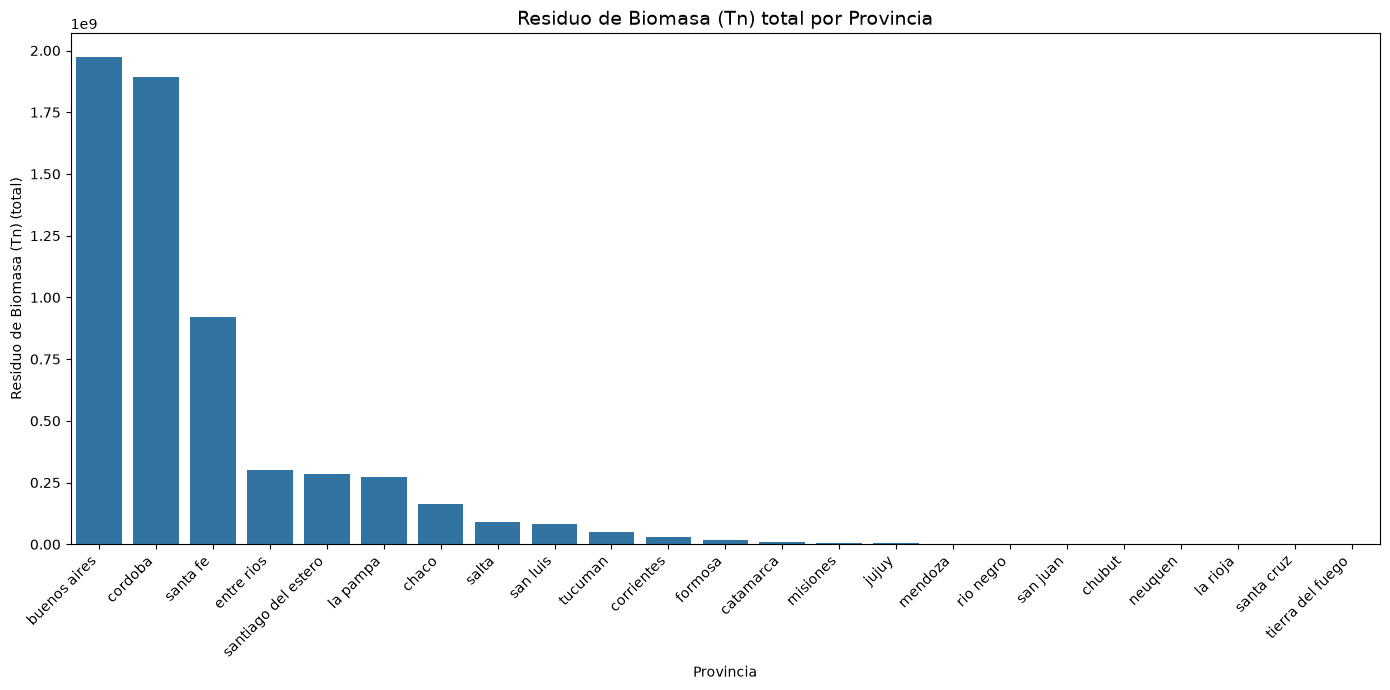

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agregar biomasa por provincia (todos los cultivos y campañas sumados)
df_grouped = (
    df_biomasa
    .groupby(["Provincia"], as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
)

# Ordenar provincias por residuo total (descendente)
order = df_grouped.sort_values("Residuo de Biomasa (Tn)", ascending=False)["Provincia"]

# Gráfico de barras ordenado
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_grouped,
    x="Provincia",
    y="Residuo de Biomasa (Tn)",
    order=order
)

plt.xticks(rotation=45, ha="right")
plt.title("Residuo de Biomasa (Tn) total por Provincia", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn) (total)")
plt.xlabel("Provincia")
plt.tight_layout()
plt.show()


## Mayor Produccion de Biomasa Residual por Cultivo 

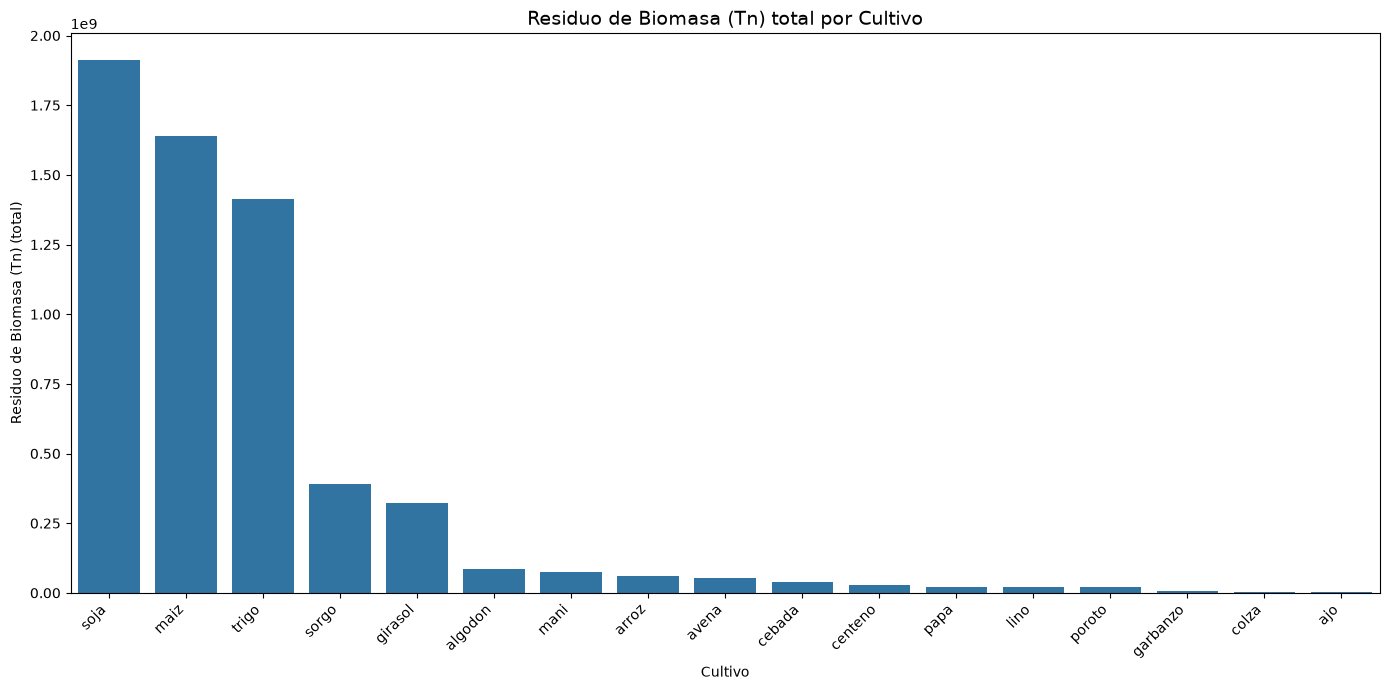

In [110]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agregar biomasa por provincia (todos los cultivos y campañas sumados)
df_grouped = (
    df_biomasa
    .groupby(["Cultivo"], as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
)

# Ordenar provincias por residuo total (descendente)
order = df_grouped.sort_values("Residuo de Biomasa (Tn)", ascending=False)["Cultivo"]

# Gráfico de barras ordenado
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_grouped,
    x="Cultivo",
    y="Residuo de Biomasa (Tn)",
    order=order
)

plt.xticks(rotation=45, ha="right")
plt.title("Residuo de Biomasa (Tn) total por Cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn) (total)")
plt.xlabel("Cultivo")
plt.tight_layout()
plt.show()


C:\Users\Usuario\AppData\Local\Temp\ipykernel_6904\550804834.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


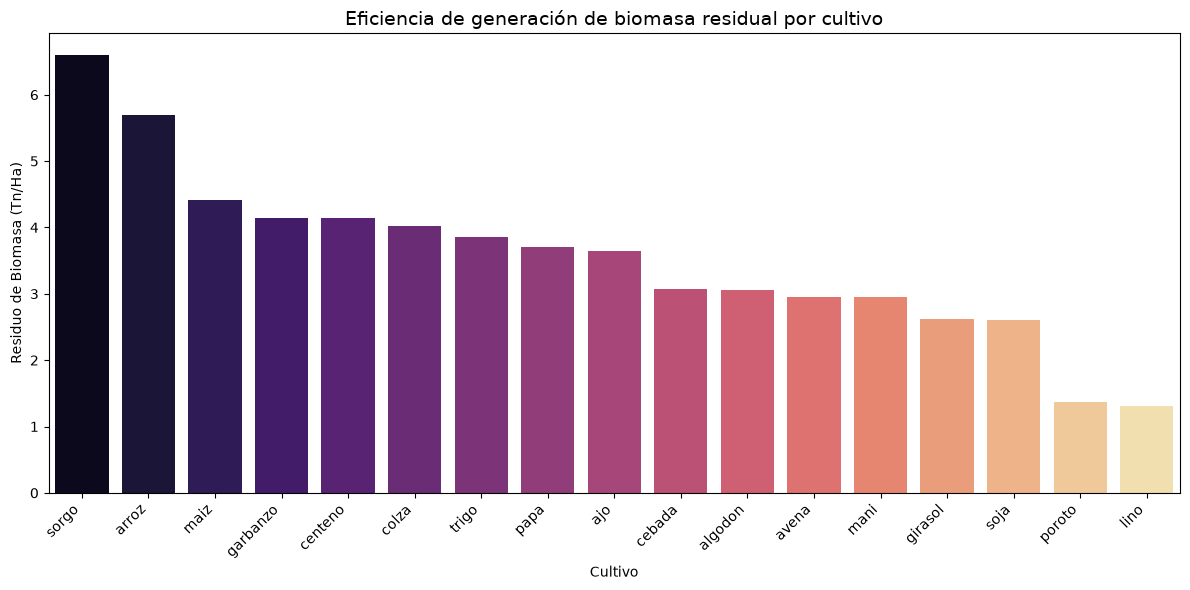

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agrupar por cultivo y calcular promedio de residuo por hectárea
df_efficiency = (
    df_biomasa
    .groupby("Cultivo", as_index=False)["Residuo de Biomasa (Tn/Ha)"]
    .mean()
    .sort_values("Residuo de Biomasa (Tn/Ha)", ascending=False)
)


plt.figure(figsize=(12,6))
sns.barplot(
    data=df_efficiency,
    x="Cultivo",
    y="Residuo de Biomasa (Tn/Ha)",
    palette="magma"
)
plt.xticks(rotation=45, ha="right")
plt.title("Eficiencia de generación de biomasa residual por cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn/Ha)")
plt.xlabel("Cultivo")
plt.tight_layout()
plt.show()